## Wind Prediction with the Selected k

This experiment measures how well the K-Means clusters predict the wind torque of new tasks.

Two types of wind tasks are used:

- **Evenly spaced tasks**: Tasks with wind torques evenly spaced between −0.5 and +0.5. K-Means is fitted on their average hidden states, and each cluster gets the mean wind of the evenly spaced tasks it contains.
- **Random tasks**: Tasks with wind torques random between −0.5 and +0.5. They are not used for fitting and serve as test data.

The number of clusters is selected in `kmeans_k_selection.ipynb` with the prediction strength.

The error of the wind prediction is measured with the Mean Absolute Error, each random task is assigned to its nearest cluster, and the mean wind of that cluster is used as the wind prediction.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys

sys.path.insert(0, os.path.abspath("../.."))
sys.path.insert(0, os.path.abspath(".."))
from analysis_utils import SYSTEMS, CHECKPOINT_DIR, set_seeds, load_model, collect_avg_hidden_states, task_parameters
from kmeans_utils import fit_kmeans

system = SYSTEMS["pendulum"]

num_repeats = 20
num_envs = 20
steps_per_env = 3000

set_seeds(42)

avg_hidden_states = np.load(
    CHECKPOINT_DIR / "pendulum_wind_avg_hidden_states.npy"
)

wind_values = task_parameters(system, system.sample_tasks_eval(num_envs=len(avg_hidden_states)))

k_selection = np.load(CHECKPOINT_DIR / "pendulum_wind_kmeans_k_selection.npz")
best_k = int(k_selection["best_k"])
k_values = [int(k) for k in k_selection["k_values"]]

print(avg_hidden_states.shape)
print(f"Selected k = {best_k}")

(20, 256)
Selected k = 2


In [2]:
# Create the RL2 model and load the trained weights
model = load_model(system)

### Collect Hidden States of the Random Tasks

All `num_repeats × num_envs` random tasks are rolled out once before the k search starts. Every random task is played for `steps_per_env` steps. The k search reuses their hidden states, so no new rollouts are needed for each k.

In [3]:
# For MAE calculation
all_random_wind_values = np.zeros((num_repeats, num_envs))

# Store the average hidden state of every random task
all_random_avg_hidden_states = np.zeros(
    (num_repeats, num_envs, model.feat_extractor.h_dim),
    dtype=avg_hidden_states.dtype # PyTorch calculates avg hidden state in float32
)

baseline_prediction = np.median(wind_values) # = 0.0 (evenly spaced winds)

# Storage for MAE per repetition
baseline_maes = np.zeros(num_repeats)

for repeat in range(num_repeats):

    random_env_configs = system.sample_tasks_train(num_envs=num_envs)
    random_envs = system.make_envs(random_env_configs)

    try:
        random_wind_values = task_parameters(system, random_env_configs)

        # Play every random task and average its hidden state over all steps
        all_random_avg_hidden_states[repeat] = collect_avg_hidden_states(
            model, system, random_envs, seed=1000 + repeat, steps=steps_per_env
        )
        all_random_wind_values[repeat] = random_wind_values

        # Calculate the constant baseline prediction error
        baseline_maes[repeat] = np.mean(
            np.abs(random_wind_values - baseline_prediction)
        )

        print(f"Repetition {repeat + 1}/{num_repeats} completed")

    finally:
        random_envs.close()

print(f"{num_repeats * num_envs} random tasks collected "
      f"({num_repeats} repetitions x {num_envs} tasks)")

Repetition 1/20 completed
Repetition 2/20 completed
Repetition 3/20 completed
Repetition 4/20 completed
Repetition 5/20 completed
Repetition 6/20 completed
Repetition 7/20 completed
Repetition 8/20 completed
Repetition 9/20 completed
Repetition 10/20 completed
Repetition 11/20 completed
Repetition 12/20 completed
Repetition 13/20 completed
Repetition 14/20 completed
Repetition 15/20 completed
Repetition 16/20 completed
Repetition 17/20 completed
Repetition 18/20 completed
Repetition 19/20 completed
Repetition 20/20 completed
400 random tasks collected (20 repetitions x 20 tasks)


### MAE for every k

For every k tested in `kmeans_k_selection.ipynb`, the following steps are performed:

1. **Clustering:** K-Means is fitted on the average hidden states of the evenly spaced tasks. It is run with multiple initializations (`n_init`), and the solution with the lowest inertia is used, so the result does not depend on the initial centroids. Each cluster gets the mean wind torque of the evenly spaced tasks it contains.
2. **Mean MAE:** the hidden state of each random task is assigned to the nearest cluster centroid, and the mean wind of that cluster is used as the wind prediction. The absolute errors between actual and predicted wind are averaged per repetition (MAE) and then over all repetitions (Mean MAE).

Only the selected k is used for the wind prediction below. The other k values are listed for comparison.

> **Note:** The clusters are fitted only on the hidden states of the evenly spaced tasks, not on the random tasks. The evenly spaced tasks cover the whole wind range uniformly, so no wind range is over- or underrepresented, and they are identical in every run. The random tasks are only assigned to the existing clusters and serve as unseen test data.

In [4]:
def evaluate_k(k):
    # Fit K-Means on the hidden states of the evenly spaced tasks
    kmeans = fit_kmeans(avg_hidden_states, k)
    cluster_assignments = kmeans.labels_

    # Stop if a cluster is empty (wont be better for more k's)
    if len(np.unique(cluster_assignments)) < k:
        return None

    # Calculate the mean wind of the evenly spaced tasks in each cluster
    cluster_wind_means = np.array([
        np.mean(wind_values[cluster_assignments == cluster])
        for cluster in range(k)
    ])

    # Storage for MAE per repetition
    cluster_maes = np.zeros(num_repeats)

    for repeat in range(num_repeats):

        # Assign the hidden states of the random tasks to the existing clusters
        random_cluster_assignments = kmeans.predict(all_random_avg_hidden_states[repeat])

        # Predict wind torques using the cluster_wind_means
        predicted_wind = cluster_wind_means[random_cluster_assignments]

        cluster_maes[repeat] = np.mean(
            np.abs(all_random_wind_values[repeat] - predicted_wind)
        )

    return kmeans, cluster_assignments, cluster_wind_means, cluster_maes


tested_k_values = []
mae_per_k = []
kmeans_models = {}
cluster_assignments_per_k = {}
cluster_wind_means_per_k = {}

for k in k_values:

    result = evaluate_k(k)

    if result is None:
        print(f"k = {k}: K-Means found fewer than {k} clusters, skipped.")
        continue

    kmeans, cluster_assignments, cluster_wind_means, cluster_maes = result

    tested_k_values.append(k)
    mae_per_k.append(cluster_maes)
    kmeans_models[k] = kmeans
    cluster_assignments_per_k[k] = cluster_assignments
    cluster_wind_means_per_k[k] = cluster_wind_means

    print(f"k = {k}: Mean MAE = {np.mean(cluster_maes):.3f}")

assert best_k in kmeans_models, f"The selected k = {best_k} could not be evaluated"

k = 2: Mean MAE = 0.128
k = 3: Mean MAE = 0.087
k = 4: Mean MAE = 0.066
k = 5: Mean MAE = 0.055
k = 6: Mean MAE = 0.047
k = 7: Mean MAE = 0.049
k = 8: Mean MAE = 0.045
k = 9: Mean MAE = 0.044
k = 10: Mean MAE = 0.042


In [5]:
# Combine the MAEs into one array with shape (num_repeats, number of tested k)
mae_results = np.column_stack(mae_per_k)

# Calculate mean and standard deviation across repetitions
mean_mae = np.mean(mae_results, axis=0)
std_mae = np.std(mae_results, axis=0, ddof=1)

baseline_mean = np.mean(baseline_maes)
baseline_std = np.std(baseline_maes, ddof=1)

print(f"{'k':>3} | {'Mean MAE':>8} | {'Std':>5}")

for j, k in enumerate(tested_k_values):
    marker = "  <- selected" if k == best_k else ""
    print(f"{k:>3} | {mean_mae[j]:>8.3f} | {std_mae[j]:>5.3f}{marker}")

print(
    f"\nBaseline: Mean MAE = {baseline_mean:.3f}, "
    f"Std = {baseline_std:.3f}"
)

  k | Mean MAE |   Std
  2 |    0.128 | 0.019  <- selected
  3 |    0.087 | 0.006
  4 |    0.066 | 0.009
  5 |    0.055 | 0.008
  6 |    0.047 | 0.007
  7 |    0.049 | 0.008
  8 |    0.045 | 0.007
  9 |    0.044 | 0.007
 10 |    0.042 | 0.007

Baseline: Mean MAE = 0.256, Std = 0.026


### Wind Ranges of the Selected k

Each cluster of the selected k is listed with the wind torques of the evenly spaced tasks it contains.

The figure below shows how well the selected k predicts the wind of all random tasks. The random tasks of all repetitions are grouped by their actual wind torque:

- **(a)** the mean predicted wind torque in each wind range. Each cluster predicts the mean wind of its evenly spaced tasks, so the line follows the dashed line of a perfect prediction in steps.
- **(b)** the mean absolute error in each wind range, compared to the constant baseline that always predicts 0.

In [6]:
best_cluster_assignments = cluster_assignments_per_k[best_k]
best_cluster_wind_means = cluster_wind_means_per_k[best_k]

print(f"Clusters for k = {best_k}, sorted by mean wind:\n")

# Sort the clusters by their mean wind for readability
for cluster in np.argsort(best_cluster_wind_means):
    cluster_winds = wind_values[best_cluster_assignments == cluster]

    print(
        f"Cluster {cluster}: Mean Wind = {best_cluster_wind_means[cluster]:6.3f} | "
        f"Range = {cluster_winds.min():6.3f} to {cluster_winds.max():6.3f} | "
        f"Winds = {np.round(cluster_winds, 3)}"
    )

Clusters for k = 2, sorted by mean wind:

Cluster 1: Mean Wind = -0.237 | Range = -0.500 to  0.026 | Winds = [-0.5   -0.447 -0.395 -0.342 -0.289 -0.237 -0.184 -0.132 -0.079 -0.026
  0.026]
Cluster 0: Mean Wind =  0.289 | Range =  0.079 to  0.500 | Winds = [0.079 0.132 0.184 0.237 0.289 0.342 0.395 0.447 0.5  ]


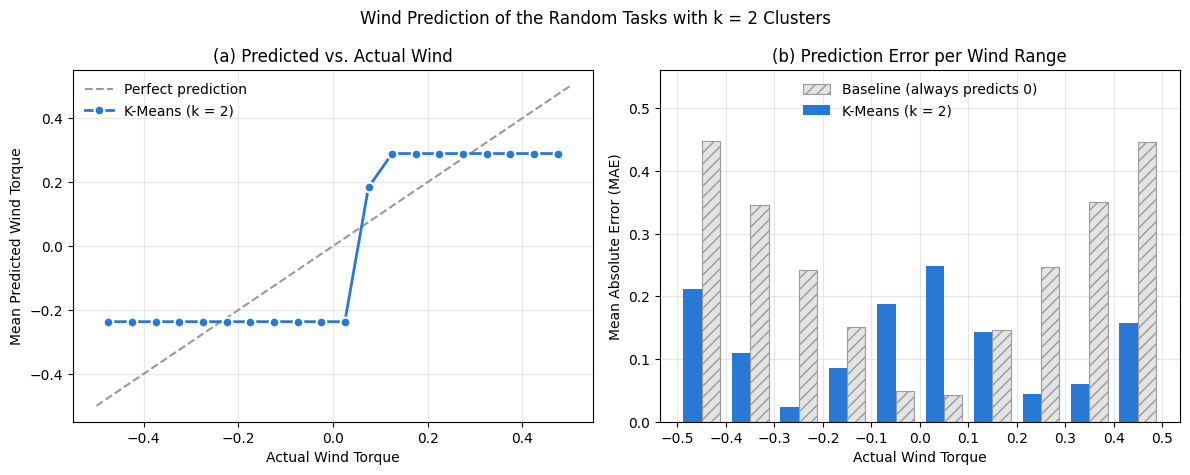

In [7]:
# Blue for K-Means, gray for references
KMEANS_COLOR = "#2a78d6"
REFERENCE_COLOR = "#999999"
# Lighter, hatched gray for the baseline bars, so they are not confused with the perfect prediction line
BASELINE_FILL_COLOR = "#e3e3e3"
BASELINE_HATCH_COLOR = "#9a9a9a"

best_kmeans = kmeans_models[best_k]
best_cluster_wind_means = cluster_wind_means_per_k[best_k]

# All random tasks of all repetitions as one flat list
flat_random_hidden_states = all_random_avg_hidden_states.reshape(-1, all_random_avg_hidden_states.shape[-1])
flat_random_wind_values = all_random_wind_values.reshape(-1)

# Predict the wind of every random task with the mean wind of its cluster
flat_random_cluster_assignments = best_kmeans.predict(flat_random_hidden_states)
flat_predicted_wind = best_cluster_wind_means[flat_random_cluster_assignments]
flat_kmeans_errors = np.abs(flat_random_wind_values - flat_predicted_wind)
# The baseline always predicts the median of the evenly spaced winds (0)
flat_baseline_errors = np.abs(flat_random_wind_values - np.median(wind_values))


def mean_per_wind_range(values, bin_edges):
    # Mean of the values of all random tasks whose actual wind lies in each wind range
    bin_index = np.clip(np.digitize(flat_random_wind_values, bin_edges) - 1, 0, len(bin_edges) - 2)
    return np.array([
        np.mean(values[bin_index == b]) if np.any(bin_index == b) else np.nan
        for b in range(len(bin_edges) - 1)
    ])


# (a) Fine wind ranges of 0.05 for the prediction line
line_edges = np.linspace(-0.5, 0.5, 21)
line_centers = (line_edges[:-1] + line_edges[1:]) / 2
mean_predicted_per_range = mean_per_wind_range(flat_predicted_wind, line_edges)

# (b) Wind ranges of 0.1 for the error bars
bar_edges = np.linspace(-0.5, 0.5, 11)
bar_centers = (bar_edges[:-1] + bar_edges[1:]) / 2
kmeans_mae_per_range = mean_per_wind_range(flat_kmeans_errors, bar_edges)
baseline_mae_per_range = mean_per_wind_range(flat_baseline_errors, bar_edges)

# Plotting
plot_name = "pendulum_kmeans_wind_prediction.png"
save_path = os.path.join("diagrams", plot_name)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# (a) Mean predicted wind per wind range
axes[0].plot(
    [-0.5, 0.5], [-0.5, 0.5],
    color=REFERENCE_COLOR, linewidth=1.5, linestyle="--", label="Perfect prediction"
)
axes[0].plot(
    line_centers, mean_predicted_per_range,
    color=KMEANS_COLOR, linewidth=2,
    marker="o", markersize=7, markeredgecolor="white", markeredgewidth=1.5,
    label=f"K-Means (k = {best_k})"
)
axes[0].set_xlim(-0.55, 0.55)
axes[0].set_ylim(-0.55, 0.55)
axes[0].set_xlabel("Actual Wind Torque")
axes[0].set_ylabel("Mean Predicted Wind Torque")
axes[0].set_title("(a) Predicted vs. Actual Wind")
axes[0].legend(loc="upper left", frameon=False)

# (b) Mean absolute error per wind range, K-Means next to the baseline
# The baseline is drawn first, so it is listed first in the legend, as in (a)
bar_width = 0.038
axes[1].bar(
    bar_centers + bar_width / 2, baseline_mae_per_range,
    width=bar_width, facecolor=BASELINE_FILL_COLOR,
    edgecolor=BASELINE_HATCH_COLOR, linewidth=0.8, hatch="///",
    label="Baseline (always predicts 0)"
)
axes[1].bar(
    bar_centers - bar_width / 2, kmeans_mae_per_range,
    width=bar_width, color=KMEANS_COLOR, label=f"K-Means (k = {best_k})"
)
axes[1].set_xticks(bar_edges)
axes[1].set_xticklabels([f"{e:.1f}".replace("-", "−") for e in bar_edges])
axes[1].set_xlabel("Actual Wind Torque")
axes[1].set_ylabel("Mean Absolute Error (MAE)")
axes[1].set_title("(b) Prediction Error per Wind Range")
axes[1].legend(loc="upper center", frameon=False)
axes[1].set_ylim(0, np.nanmax([kmeans_mae_per_range, baseline_mae_per_range]) * 1.25)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle(f"Wind Prediction of the Random Tasks with k = {best_k} Clusters")
fig.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

In [8]:
# Save the results and corresponding rollout data.
np.savez(
    CHECKPOINT_DIR / "pendulum_wind_kmeans_repeated_eval.npz",
    k_values=np.array(tested_k_values),
    best_k=best_k,
    mae_results=mae_results,
    baseline_maes=baseline_maes,
    random_wind_values=all_random_wind_values,
    random_avg_hidden_states=all_random_avg_hidden_states
)

print("Repeated evaluation results saved.")

Repeated evaluation results saved.
